In [3]:
import pandas as pd
import numpy as np

data = pd.read_csv("test.csv")
df = pd.DataFrame(data)
print("Original Dataset")
print(df)

Original Dataset
      experience    country     education         languages  \
0             10  Singapore     Bachelors    JavaScript, Go   
1             13        USA  Some College         PHP, Java   
2             28      India  Some College    JavaScript, C#   
3             16     Brazil     Bachelors  Ruby, JavaScript   
4             20  Singapore           PhD        Java, Java   
...          ...        ...           ...               ...   
9995          16        USA     Bachelors         PHP, Rust   
9996          29        USA       Masters  JavaScript, Ruby   
9997           3        USA       Masters          C++, PHP   
9998          35     Canada       Masters      Python, Rust   
9999          28        USA       Masters       C++, Python   

                frameworks company_size  salary_usd  
0          Spring, Express         1-10       68491  
1     Flask, Ruby on Rails       51-200      120045  
2              Vue, Spring       51-200       87811  
3         

In [4]:

from sklearn.preprocessing import MinMaxScaler
import pandas as pd
import numpy as np

data = pd.read_csv("test.csv")
df = pd.DataFrame(data)

# Select numerical columns only
numeric_cols = df.select_dtypes(include=np.number).columns

# Initialize MinMaxScaler
scaler = MinMaxScaler()

# Apply normalization to numerical columns
normalized_df = df.copy()
normalized_df[numeric_cols] = scaler.fit_transform(df[numeric_cols])

print("Normalized Dataset:")
print(normalized_df.round(2))

# Verify minimum and maximum values
print("\nMinimum values:")
print(normalized_df[numeric_cols].min())

print("\nMaximum values:")
print(normalized_df[numeric_cols].max())




Normalized Dataset:
      experience    country     education         languages  \
0           0.25  Singapore     Bachelors    JavaScript, Go   
1           0.32        USA  Some College         PHP, Java   
2           0.70      India  Some College    JavaScript, C#   
3           0.40     Brazil     Bachelors  Ruby, JavaScript   
4           0.50  Singapore           PhD        Java, Java   
...          ...        ...           ...               ...   
9995        0.40        USA     Bachelors         PHP, Rust   
9996        0.73        USA       Masters  JavaScript, Ruby   
9997        0.08        USA       Masters          C++, PHP   
9998        0.88     Canada       Masters      Python, Rust   
9999        0.70        USA       Masters       C++, Python   

                frameworks company_size  salary_usd  
0          Spring, Express         1-10        0.21  
1     Flask, Ruby on Rails       51-200        0.40  
2              Vue, Spring       51-200        0.28  
3      

In [8]:

from sklearn.preprocessing import StandardScaler
import pandas as pd
import numpy as np

data = pd.read_csv("test.csv")
df = pd.DataFrame(data)

# Select numeric columns only
numeric_cols = df.select_dtypes(include=np.number).columns

# Initialize StandardScaler
scaler = StandardScaler()

# Apply standardization only to numeric columns
standardized_data = scaler.fit_transform(df[numeric_cols])

# Convert standardized data into a DataFrame
standardized_df = pd.DataFrame(
    standardized_data,
    columns=numeric_cols
)

# Replace the original numeric columns with standardized values
df[numeric_cols] = standardized_df

print("Standardized Dataset:")
print(df.round(2))

# Verify mean of numeric features
print("\nMean of each numeric feature:")
print(df[numeric_cols].mean().round(2))

# Verify standard deviation of numeric features
print("\nStandard deviation of each numeric feature:")
print(df[numeric_cols].std(ddof=0).round(2))


Standardized Dataset:
      experience    country     education         languages  \
0          -0.82  Singapore     Bachelors    JavaScript, Go   
1          -0.57        USA  Some College         PHP, Java   
2           0.69      India  Some College    JavaScript, C#   
3          -0.32     Brazil     Bachelors  Ruby, JavaScript   
4           0.02  Singapore           PhD        Java, Java   
...          ...        ...           ...               ...   
9995       -0.32        USA     Bachelors         PHP, Rust   
9996        0.78        USA       Masters  JavaScript, Ruby   
9997       -1.41        USA       Masters          C++, PHP   
9998        1.28     Canada       Masters      Python, Rust   
9999        0.69        USA       Masters       C++, Python   

                frameworks company_size  salary_usd  
0          Spring, Express         1-10       -1.35  
1     Flask, Ruby on Rails       51-200       -0.24  
2              Vue, Spring       51-200       -0.93  
3    

PCA Transformed Data:
       PC1   PC2
0    -1.53  0.37
1    -0.57 -0.23
2    -0.17  1.15
3    -0.71  0.26
4    -0.33  0.36
...    ...   ...
9995  0.37 -0.82
9996  1.35 -0.25
9997 -1.28 -0.72
9998  1.07  0.75
9999  1.72 -0.75

[10000 rows x 2 columns]

Explained Variance Ratio:
[0.8868 0.1132]

Total Variance Retained:
1.0


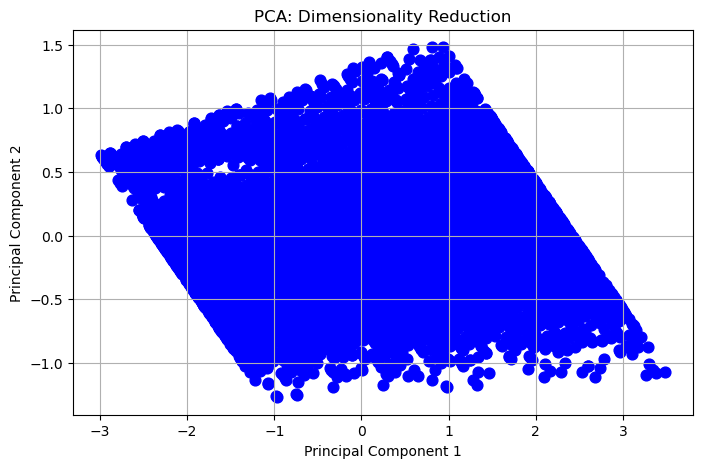

In [9]:

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load the dataset
data = pd.read_csv("test.csv")
df = pd.DataFrame(data)

# Select only numerical columns
numeric_cols = df.select_dtypes(include=np.number).columns

# Standardize the numerical data
scaler = StandardScaler()
scaled_data = scaler.fit_transform(df[numeric_cols])

# Apply PCA to reduce features to 2 components
pca = PCA(n_components=2)
pca_data = pca.fit_transform(scaled_data)

# Create a DataFrame
pca_df = pd.DataFrame(
    pca_data,
    columns=['PC1', 'PC2']
)

print("PCA Transformed Data:")
print(pca_df.round(2))

# Explained variance
print("\nExplained Variance Ratio:")
print(pca.explained_variance_ratio_.round(4))

# Total variance retained
print("\nTotal Variance Retained:")
print(round(pca.explained_variance_ratio_.sum(), 4))

# Visualize PCA output
plt.figure(figsize=(8, 5))
plt.scatter(
    pca_df['PC1'],
    pca_df['PC2'],
    color='blue',
    s=60
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA: Dimensionality Reduction")
plt.grid(True)
plt.show()
